# Week 45, Monday lecture: simple recurrent neural networks in TensorFlow/Keras and PyTorch

**FYS-STK3155/4155, Monday November 2, 2026**

This notebook contains the code behind every figure and number in the Monday
slides (`week45slides.pdf`). The lecture opens with a fifteen-minute recap
of convolutional networks — the Keras and PyTorch programs of week 44 are in
`week44.ipynb` and are not repeated here — and then stays with the *simple*
recurrent network of Eq. (11.4) throughout (Chapter 11, Sections 11.1–11.6
and 11.8; the gated cells of Section 11.7 are the first hour of week 46).
Every recurrent network in it is a library layer — `tf.keras.layers.SimpleRNN`
or `torch.nn.RNN` — and every gradient is computed by the libraries'
automatic differentiation. The theory of Chapter 11 (the recursion of
backpropagation through time, the product of Jacobians of Theorem 11.1) is
*measured* on those layers with `torch.autograd` rather than re-implemented.
NumPy is used only for data: the Runge–Kutta solution of the oscillator and
the one-dimensional map.

*Part 1* is where the recurrence comes from (Section 11.3): Newton's equation
for a damped oscillator, Eq. (11.8), reduced to two first-order equations and
discretised by forward Euler, Eq. (11.10). Substituting one step into the
next gives $\boldsymbol{h}_i = h(\boldsymbol{x}_i, \boldsymbol{h}_{i-1})$,
Eq. (11.13) — the recurrent network is a learned, non-linear time-stepper.

*Part 2* is the RNN as a discrete-time dynamical system (Section 11.2.1):
the one-dimensional map $h \mapsto \tanh(Wh)$, its fixed points and the
pitchfork at $W=1$, and the norm of the hidden state of an untrained
`nn.RNN` with no input — which forgets its initial condition at a geometric
rate when $\rho(\boldsymbol{W})<1$.

*Part 3* is the layers themselves (Section 11.8): what `SimpleRNN` and
`nn.RNN` compute, their parameter counts against $n_h(n_x+n_h+1)$, the same
weights loaded into both libraries, and the demonstration that
`loss.backward()` is a linear map of the output error.

*Part 4* is why long sequences are hard (Section 11.5): the Jacobian
$\partial\boldsymbol{h}^{(T)}/\partial\boldsymbol{h}^{(t)}$ of Theorem 11.1
obtained from `torch.autograd` on `nn.RNN` for four spectral radii, and the
memory horizon of Corollary 11.2 fitted to the decay.

*Part 5* is the oscillator experiment (Section 11.6.1) in Keras and in
PyTorch: a simple RNN with $n_h=24$ trained on one trajectory, tested on an
initial condition and a forcing it never saw.

*Part 6* is three applications: the sine-wave forecast, MNIST read row by
row, and the adding problem at increasing sequence length — the experiment
that shows where the memory horizon of a simple recurrent network runs out.

The functions are the ones in `make_week45_figures.py`. Parts 1–4 run in
about a minute, Part 5 in two to three minutes, and Part 6 in four to five
minutes on a laptop CPU. PyTorch and TensorFlow are needed throughout
(`pip install torch tensorflow`). The MNIST data are read from `mnist.npz`
in this folder.

**Tomorrow** (Tuesday) is a work session for Project 2, which is due
**Monday November 9**; there are no weekly exercises this week.

In [1]:
import glob
import os
import subprocess
import time
import wave
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
%matplotlib inline

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "")
import torch
# torch and tensorflow ship different LLVM runtimes; torch loads part of its
# optimiser machinery lazily at the first optimizer.step(), which crashes if
# tensorflow was imported in between.  So: torch first, one dummy step, then tf.
_p = torch.nn.Parameter(torch.zeros(1))
_p.grad = torch.zeros(1)
torch.optim.Adam([_p]).step()
import tensorflow as tf

BLUE, RED, YELLOW, GREY, GREEN = "#004488", "#BB5566", "#DDAA33", "#777777", "#228833"
plt.rcParams.update({"font.size": 10, "axes.titlesize": 10, "legend.fontsize": 8.5,
                     "figure.dpi": 110})
HERE = os.getcwd()


def savefig(fig, name):
    fig.savefig(os.path.join(HERE, name + ".png"), bbox_inches="tight", dpi=150)
    plt.show()

I0000 00:00:1793550083.119420     407 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## Part 1: where the recurrence comes from — a differential equation (Section 11.3)

Almost everything in the course so far has assumed independent and
identically distributed samples and a fixed input dimension. A sequence
breaks both: the value of a detector trace at one sample is strongly
informative about the next (that *is* the signal), and sequences come in
different lengths. A recurrent network processes one element at a time and
carries a **state** forward, Eq. (11.3),

$$\boldsymbol{h}_t = f_\theta(\boldsymbol{h}_{t-1}, \boldsymbol{x}_t), \qquad
\hat{\boldsymbol{y}}_t = g_\theta(\boldsymbol{h}_t),$$

which is exactly the structure of a Markovian dynamical system with a learned
update map. The recurrence is not arbitrary. Take Newton's equation for a
damped harmonic oscillator in dimensionless time, Eq. (11.8),

$$\frac{d^2x}{dt^2} + \eta\frac{dx}{dt} + x(t) = F(t),$$

rewrite it as two first-order equations, Eq. (11.9), $v = dx/dt$ and
$dv/dt = F - \eta v - x$, and discretise the velocity equation by forward
Euler, Eq. (11.10),

$$v_{i+1} = v_i + \Delta t\,(F_i - \eta v_i - x_i) =: h_i(x_i, v_i, F_i).$$

The right-hand side is a function of the current state and the current
input; but $v_i$ was produced by the same rule one step earlier, so
$v_{i+1} = h_i(x_i, h_{i-1}, F_i)$, Eq. (11.12), which after renaming is
Eq. (11.13), $\boldsymbol{h}_i = h(\boldsymbol{x}_i, \boldsymbol{h}_{i-1})$.
The hidden state plays the role of the integrator's internal state,
$\boldsymbol{W}$ plays the role of $1 - \eta\Delta t$, and the training data
supply what the differential equation would otherwise have to tell us.

Below: the Runge–Kutta solution we use as data, the forward-Euler
recurrence written so that its state-and-input structure is visible, and the
two test trajectories (an unseen initial condition and a driven oscillator)
of Part 5. Compare with week 42: there the equation was known and supplied
the cost through its residual; here the equation is unknown and the data
supply the cost.

In [2]:
ETA = 0.2                      # the damping of Eq. (11.8)


def oscillator_deriv(s, t, F=lambda t: 0.0, eta=ETA):
    """Eq. (11.9): the two first-order equations for (x, v)."""
    x, v = s
    return np.array([v, F(t) - eta * v - x])


def rk4(s0, ts, F=lambda t: 0.0, eta=ETA):
    """Fourth-order Runge-Kutta for Eq. (11.9); returns S[i] = (x_i, v_i)."""
    S = np.zeros((len(ts), 2))
    S[0] = s0
    for i in range(len(ts) - 1):
        h = ts[i + 1] - ts[i]
        s, t = S[i], ts[i]
        k1 = oscillator_deriv(s, t, F, eta)
        k2 = oscillator_deriv(s + 0.5 * h * k1, t + 0.5 * h, F, eta)
        k3 = oscillator_deriv(s + 0.5 * h * k2, t + 0.5 * h, F, eta)
        k4 = oscillator_deriv(s + h * k3, t + h, F, eta)
        S[i + 1] = s + h * (k1 + 2 * k2 + 2 * k3 + k4) / 6
    return S


def euler_recurrence(x0, v0, ts, F=lambda t: 0.0, eta=ETA):
    """The forward-Euler step of Eq. (11.10), v_{i+1} = h_i(x_i, v_i, F_i).

    Written so that the recurrent structure is visible: the state carried
    from one step to the next is (x_i, v_i), the input at step i is F_i.
    """
    dt = ts[1] - ts[0]
    x, v = np.zeros(len(ts)), np.zeros(len(ts))
    x[0], v[0] = x0, v0
    for i in range(len(ts) - 1):
        v[i + 1] = v[i] + dt * (F(ts[i]) - eta * v[i] - x[i])   # h_i(x_i, v_i, F_i)
        x[i + 1] = x[i] + dt * v[i]
    return x, v


def oscillator_trajectories():
    """The training trajectory and the two test trajectories of the lecture."""
    ts = np.linspace(0, 40, 800)
    S_tr = rk4([1.0, 0.0], ts)
    S_ic = rk4([0.0, 1.0], ts)
    S_dr = rk4([0.5, -0.3], ts, F=lambda t: 0.3 * np.cos(0.7 * t))
    return ts, S_tr, S_ic, S_dr


def fig_oscillator_data():
    ts, S_tr, S_ic, S_dr = oscillator_trajectories()
    x_eu, _ = euler_recurrence(1.0, 0.0, ts)
    fig, ax = plt.subplots(1, 3, figsize=(12, 3.1))
    ax[0].plot(ts, S_tr[:, 0], color=BLUE, label="$x(t)$, RK4")
    ax[0].plot(ts, S_tr[:, 1], color=GREY, lw=0.9, label="$v(t)$")
    ax[0].plot(ts, x_eu, "--", color=RED, lw=0.9, label="$x(t)$, forward Euler, Eq. (11.10)")
    ax[0].set_title("(a) training trajectory, $(x_0,v_0)=(1,0)$, $\\eta=0.2$")
    ax[1].plot(ts, S_ic[:, 0], color=BLUE)
    ax[1].set_title("(b) unseen initial condition $(0,1)$")
    ax[2].plot(ts, S_dr[:, 0], color=BLUE)
    ax[2].set_title("(c) driven, $F(t)=0.3\\cos(0.7t)$, IC $(0.5,-0.3)$")
    for a in ax:
        a.set_xlabel("$t$")
        a.axhline(0, color="k", lw=0.4)
    ax[0].legend(loc="upper right")
    fig.tight_layout()
    savefig(fig, "week45_oscillator_data")
    plt.close(fig)
    err = np.max(np.abs(x_eu - S_tr[:, 0]))
    print(f"[Part 1] forward Euler against RK4 on the training trajectory: "
          f"max |x_Euler - x_RK4| = {err:.3e} at dt = {ts[1]-ts[0]:.4f}")
    return ts, S_tr, S_ic, S_dr


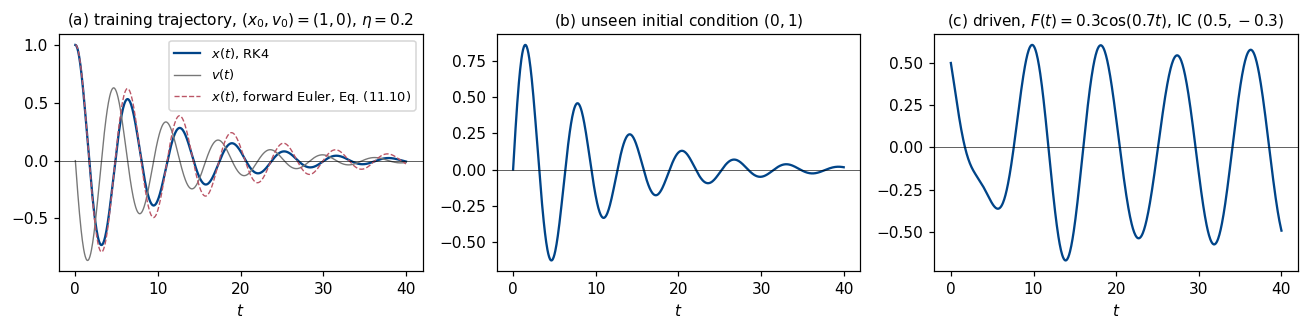

[Part 1] forward Euler against RK4 on the training trajectory: max |x_Euler - x_RK4| = 1.058e-01 at dt = 0.0501


In [3]:
ts, S_tr, S_ic, S_dr = fig_oscillator_data()

## Part 2: the RNN as a discrete-time dynamical system (Section 11.2.1)

The simple RNN, Eq. (11.4), is

$$\boldsymbol{a}^{(t)} = \boldsymbol{U}\boldsymbol{x}^{(t)} + \boldsymbol{W}\boldsymbol{h}^{(t-1)} + \boldsymbol{b},\quad
\boldsymbol{h}^{(t)} = \sigma_h(\boldsymbol{a}^{(t)}),\quad
\boldsymbol{o}^{(t)} = \boldsymbol{V}\boldsymbol{h}^{(t)} + \boldsymbol{c},\quad
\hat{\boldsymbol{y}}^{(t)} = \sigma_y(\boldsymbol{o}^{(t)}),$$

with the *same* $\boldsymbol{U}, \boldsymbol{W}, \boldsymbol{V}$ at every
step (parameter sharing in time, the analogue of the parameter sharing in
space of a convolution) and the cost accumulated over the sequence,
Eq. (11.5). Set the input to zero and Eq. (11.4) becomes an autonomous map,
Eq. (11.6), $\boldsymbol{h}^{(t)} = F(\boldsymbol{h}^{(t-1)}) =
\sigma_h(\boldsymbol{W}\boldsymbol{h}^{(t-1)} + \boldsymbol{b})$, whose
fixed points are stable when the spectral radius of the Jacobian
$\boldsymbol{J} = \mathrm{diag}(\sigma_h'(\boldsymbol{a}^\star))\boldsymbol{W}$,
Eq. (11.7), is below one.

In one dimension, $h \mapsto \tanh(Wh)$: $0$ is always a fixed point, stable
for $|W|<1$; at $W=1$ a pitchfork bifurcation produces two stable non-zero
fixed points. A network with $|W|<1$ *forgets* its initial condition at the
rate $|W|^t$ — and in Part 4 the same number reappears as the size of the
gradient that travels $t$ steps backwards.

The twenty-dimensional network of panel (c) is a PyTorch `nn.RNN` whose
recurrent matrix `weight_hh_l0` has been rescaled to a prescribed spectral
radius (`scaled_rnn`, reused in Part 4) and which is driven by zero input
from a random initial state of norm one.

In [4]:
def tanh_map_iterates(W, h0=0.9, n=30):
    """Iterates of the one-dimensional autonomous map h -> tanh(W h), Eq. (11.6)."""
    h = np.zeros(n + 1)
    h[0] = h0
    for t in range(n):
        h[t + 1] = np.tanh(W * h[t])
    return h


def tanh_fixed_point(W, tol=1e-14):
    """The positive fixed point h* = tanh(W h*) for W > 1 (0 otherwise), by bisection."""
    if W <= 1.0:
        return 0.0
    lo, hi = 1e-12, 1.0
    for _ in range(200):
        mid = 0.5 * (lo + hi)
        if np.tanh(W * mid) - mid > 0:
            lo = mid
        else:
            hi = mid
        if hi - lo < tol:
            break
    return 0.5 * (lo + hi)


def scaled_rnn(rho, n_h=20, n_x=1, seed=3):
    """An untrained torch nn.RNN (tanh, one layer) whose recurrent matrix W has
    spectral radius rho; biases zero, input matrix U standard normal.
    Returns the layer and the spectral norm sigma_max(W)."""
    import torch
    import torch.nn as nn
    torch.manual_seed(seed)
    rnn = nn.RNN(n_x, n_h, batch_first=True)
    with torch.no_grad():
        W = torch.randn(n_h, n_h, dtype=torch.float64)
        W *= rho / np.max(np.abs(np.linalg.eigvals(W.numpy())))
        rnn.weight_hh_l0.copy_(W.float())
        rnn.weight_ih_l0.copy_(torch.randn(n_h, n_x))
        rnn.bias_ih_l0.zero_()
        rnn.bias_hh_l0.zero_()
    return rnn, float(np.linalg.norm(W.numpy(), 2))


def autonomous_norms(rho, n_h=20, T=60, seed=3):
    """||h_t|| for an untrained nn.RNN driven by zero input, Eq. (11.6), starting
    from a random h_0 of norm one: W scaled to spectral radius rho."""
    import torch
    rnn, _ = scaled_rnn(rho, n_h, seed=seed)
    g = torch.Generator().manual_seed(seed)
    h0 = torch.randn(1, 1, n_h, generator=g)
    h0 = h0 / h0.norm()
    X = torch.zeros(1, T, 1)                    # (batch, time, features): no input
    with torch.no_grad():
        out, _ = rnn(X, h0)                     # out[0, t] is h_{t+1}
    return np.concatenate([[1.0], out[0].norm(dim=1).numpy()])


def fig_dynamics():
    hs = np.linspace(-1.5, 1.5, 400)
    fig, ax = plt.subplots(1, 3, figsize=(12, 3.3))
    for W, c in [(0.5, BLUE), (1.0, GREY), (1.5, RED)]:
        ax[0].plot(hs, np.tanh(W * hs), color=c, label=f"$W={W}$")
    ax[0].plot(hs, hs, "k--", lw=0.7, label="$h$")
    ax[0].set_xlabel("$h^{(t-1)}$")
    ax[0].set_ylabel("$h^{(t)}=\\tanh(Wh^{(t-1)})$")
    ax[0].set_title("(a) the one-dimensional map, Eq. (11.6)")
    ax[0].legend()
    for W, c in [(0.5, BLUE), (1.0, GREY), (1.5, RED)]:
        h = tanh_map_iterates(W)
        ax[1].plot(h, "o-", ms=3, color=c, label=f"$W={W}$")
        if W > 1:
            ax[1].axhline(tanh_fixed_point(W), color=c, lw=0.6, ls=":")
    ax[1].set_xlabel("step $t$")
    ax[1].set_ylabel("$h^{(t)}$ from $h^{(0)}=0.9$")
    ax[1].set_title("(b) iterates: forget ($W<1$) or remember ($W>1$)")
    ax[1].legend()
    for rho, c in [(0.5, BLUE), (0.9, GREEN), (1.1, YELLOW), (1.5, RED)]:
        ax[2].semilogy(autonomous_norms(rho), color=c, label=f"$\\rho(W)={rho}$")
    ax[2].set_xlabel("step $t$")
    ax[2].set_ylabel("$\\|h^{(t)}\\|$")
    ax[2].set_title("(c) nn.RNN, $n_h=20$, no input: forget, or settle on an attractor")
    ax[2].legend()
    fig.tight_layout()
    savefig(fig, "week45_dynamics")
    plt.close(fig)
    print("[Part 2] fixed points of h = tanh(W h):",
          ", ".join(f"W={W}: h*=±{tanh_fixed_point(W):.4f}" for W in [1.0, 1.2, 1.5, 2.0]))
    for W in [0.5, 0.9, 1.5]:
        h = tanh_map_iterates(W)
        print(f"         W={W}: h after 10 steps {h[10]:+.4f}, after 30 steps {h[30]:+.4f}")
    for rho in [0.5, 0.9, 1.1, 1.5]:
        n = autonomous_norms(rho)
        print(f"         rho={rho}: ||h_0||={n[0]:.3f}  ||h_10||={n[10]:.3e}  ||h_60||={n[60]:.3e}")


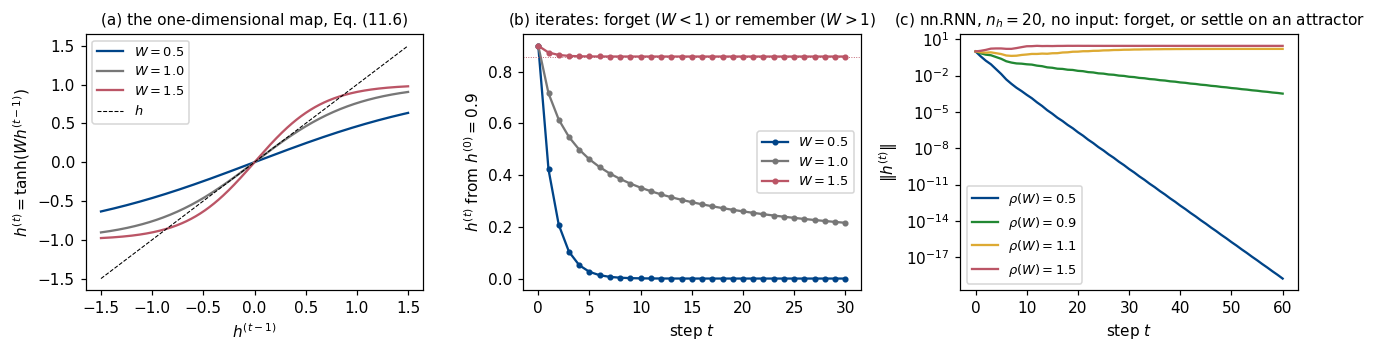

[Part 2] fixed points of h = tanh(W h): W=1.0: h*=±0.0000, W=1.2: h*=±0.6586, W=1.5: h*=±0.8586, W=2.0: h*=±0.9575
         W=0.5: h after 10 steps +0.0008, after 30 steps +0.0000
         W=0.9: h after 10 steps +0.1789, after 30 steps +0.0208
         W=1.5: h after 10 steps +0.8586, after 30 steps +0.8586
         rho=0.5: ||h_0||=1.000  ||h_10||=2.591e-04  ||h_60||=1.685e-19
         rho=0.9: ||h_0||=1.000  ||h_10||=8.671e-02  ||h_60||=3.261e-04
         rho=1.1: ||h_0||=1.000  ||h_10||=5.578e-01  ||h_60||=1.621e+00
         rho=1.5: ||h_0||=1.000  ||h_10||=2.687e+00  ||h_60||=2.888e+00


In [5]:
fig_dynamics()

## Part 3: the layers in Keras and PyTorch (Section 11.8)

Both libraries want a 3-tensor of shape `(samples, timesteps, features)`
$=(N, T, n_x)$; in PyTorch this needs `batch_first=True`. A Keras model for
one-step forecasting at every step of a window is

```python
model = keras.Sequential([keras.Input(shape=(None, 1)),               # (T, n_x), T may vary
                          layers.SimpleRNN(24, return_sequences=True), # Eq. (11.4): every h_t
                          layers.Dense(1)])                            # V h_t + c at every step
model.compile(optimizer=keras.optimizers.Adam(5e-3, clipnorm=1.0), loss="mse")
model.fit(X_train, Y_train, epochs=300, batch_size=4)
```

and the same in PyTorch separates the definition from the training loop:

```python
class Forecaster(nn.Module):
    def __init__(self, n_h=24):
        super().__init__()
        self.rnn = nn.RNN(1, n_h, batch_first=True)   # Eq. (11.4), tanh
        self.fc = nn.Linear(n_h, 1)                    # V h_t + c
    def forward(self, x):
        H, h_T = self.rnn(x)                           # H: (N, T, n_h), h_T: (1, N, n_h)
        return self.fc(H)

for epoch in range(300):
    for idx in torch.randperm(len(X_train)).split(4):
        opt.zero_grad(); loss = lossfn(model(X_train[idx]), Y_train[idx])
        loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
```

Three things worth checking before using either. The parameter counts:
Keras prints exactly $n_h(n_x+n_h+1)$ for `SimpleRNN` (`count_layer_parameters`
also lists the gated cells of next week, four and three times that); PyTorch
is larger by $n_h$ because `nn.RNN` carries two bias vectors (`bias_ih` and
`bias_hh`) whose sum is our $\boldsymbol{b}$.
The conventions: Keras stores $\boldsymbol{U}$ and $\boldsymbol{W}$
transposed, and with the weights copied across the two layers agree to
single precision. And the backward pass: `loss.backward()` performs
backpropagation through time, Eqs. (11.15)–(11.18), which is a *fixed
linear map* of the output error — double the error and every gradient
doubles exactly (in float64).

In [6]:
def count_layer_parameters(n_x=1, n_h=24):
    """Parameter counts of the three recurrent cells in Keras and PyTorch
    against Eq. (11.4): n_h(n_x+n_h+1) for the simple RNN, four times that
    for the LSTM (four gates), three times for the GRU."""
    import torch.nn as nn
    from tensorflow import keras
    from tensorflow.keras import layers
    formula = n_h * (n_x + n_h + 1)
    print(f"[Part 3] parameters of one recurrent layer, n_x={n_x}, n_h={n_h}; "
          f"Eq. (11.4) gives n_h(n_x+n_h+1) = {formula}")
    print("           cell        Keras   PyTorch   formula   (PyTorch - Keras)/n_h")
    rows = []
    for name, K, P, k in [("simple RNN", layers.SimpleRNN, nn.RNN, 1),
                          ("LSTM", layers.LSTM, nn.LSTM, 4),
                          ("GRU", layers.GRU, nn.GRU, 3)]:
        m = keras.Sequential([keras.Input(shape=(None, n_x)), K(n_h)])
        nk = int(sum(np.prod(w.shape) for w in m.trainable_weights))
        np_ = sum(q.numel() for q in P(n_x, n_h).parameters())
        rows.append((name, nk, np_, k * formula))
        print(f"           {name:10s}  {nk:6d}  {np_:8d}  {k*formula:8d}   {(np_-nk)/n_h:.0f}")
    print("         PyTorch carries two bias vectors per gate (bias_ih and bias_hh), Keras one; "
          "the GRU in Keras uses reset_after=True, which also doubles its bias")
    return rows


def same_network_both_frameworks(n_x=2, n_h=5, T=7, seed=0):
    """Load one set of weights into nn.RNN and into SimpleRNN and compare the
    hidden states: U <-> kernel (transposed), W <-> recurrent_kernel
    (transposed), b <-> bias_ih + bias_hh.  Section 11.8.3."""
    import torch
    import torch.nn as nn
    from tensorflow import keras
    from tensorflow.keras import layers
    torch.manual_seed(seed)
    rnn = nn.RNN(n_x, n_h, batch_first=True)
    X = torch.randn(3, T, n_x)
    with torch.no_grad():
        H_torch, _ = rnn(X)                                   # (3, T, n_h): every h_t
    U = rnn.weight_ih_l0.detach().numpy()                     # (n_h, n_x)
    W = rnn.weight_hh_l0.detach().numpy()                     # (n_h, n_h)
    b = (rnn.bias_ih_l0 + rnn.bias_hh_l0).detach().numpy()    # one bias in Eq. (11.4)
    k = keras.Sequential([keras.Input(shape=(T, n_x)),
                          layers.SimpleRNN(n_h, return_sequences=True)])
    k.layers[0].set_weights([U.T, W.T, b])                    # Keras stores the transposes
    H_keras = k(X.numpy()).numpy()
    diff = np.max(np.abs(H_torch.numpy() - H_keras))
    print(f"[Part 3] the same U, W, b in nn.RNN and SimpleRNN, T={T}: "
          f"max |h_torch - h_keras| = {diff:.2e} (float32)")
    return diff


def backward_pass_is_linear(n_x=2, n_h=6, T=12, seed=0):
    """loss.backward() on nn.RNN: double the output error and every gradient
    doubles exactly -- the backward pass is a fixed linear map of the error
    (Section 11.4).  We use the cost 1/2 sum (yhat - y)^2 so that dL/dyhat is
    the error itself."""
    import torch
    import torch.nn as nn
    torch.manual_seed(seed)
    rnn, fc = nn.RNN(n_x, n_h, batch_first=True).double(), nn.Linear(n_h, 1).double()
    params = list(rnn.parameters()) + list(fc.parameters())
    X = torch.randn(1, T, n_x, dtype=torch.float64)
    with torch.no_grad():
        y0 = fc(rnn(X)[0])                      # the network's own output
    target = y0 + torch.randn_like(y0)          # error e = yhat - target
    grads = []
    for scale in (1.0, 2.0):
        for q in params:
            q.grad = None
        yhat = fc(rnn(X)[0])
        loss = 0.5 * ((yhat - (y0 + scale * (target - y0))) ** 2).sum()
        loss.backward()                         # BPTT, Eqs. (11.16)-(11.18)
        grads.append([q.grad.clone() for q in params])
    err = max(float((2 * g1 - g2).abs().max() / g2.abs().max()) for g1, g2 in zip(*grads))
    print(f"[Part 3] loss.backward() is linear in the output error: "
          f"max |g(2e) - 2 g(e)| / max|g(2e)| = {err:.2e}")
    return err


def part3_numbers():
    count_layer_parameters()
    same_network_both_frameworks()
    backward_pass_is_linear()


In [7]:
part3_numbers()

[Part 3] parameters of one recurrent layer, n_x=1, n_h=24; Eq. (11.4) gives n_h(n_x+n_h+1) = 624
           cell        Keras   PyTorch   formula   (PyTorch - Keras)/n_h
           simple RNN     624       648       624   1
           LSTM          2496      2592      2496   4
           GRU           1944      1944      1872   0
         PyTorch carries two bias vectors per gate (bias_ih and bias_hh), Keras one; the GRU in Keras uses reset_after=True, which also doubles its bias
[Part 3] the same U, W, b in nn.RNN and SimpleRNN, T=7: max |h_torch - h_keras| = 1.19e-07 (float32)
[Part 3] loss.backward() is linear in the output error: max |g(2e) - 2 g(e)| / max|g(2e)| = 2.57e-16


[Part 3] the same U, W, b in nn.RNN and SimpleRNN, T=7: max |h_torch - h_keras| = 1.19e-07 (float32)


[Part 3] loss.backward() is linear in the output error: max |g(2e) - 2 g(e)| / max|g(2e)| = 4.33e-16


## Part 4: why long sequences are hard (Sections 11.5 and 11.7.1)

Iterating Eq. (11.17) from $T$ back to $t$ produces a **product of
Jacobians**, Theorem 11.1, Eq. (11.19),

$$\frac{\partial\boldsymbol{h}^{(T)}}{\partial\boldsymbol{h}^{(t)}} = \prod_{k=t+1}^{T}\mathrm{diag}\!\left(\sigma_h'(\boldsymbol{a}^{(k)})\right)\boldsymbol{W},
\qquad
\left\|\frac{\partial\boldsymbol{h}^{(T)}}{\partial\boldsymbol{h}^{(t)}}\right\|_2 \le \left(\mu\,\sigma_{\max}(\boldsymbol{W})\right)^{T-t},$$

with $|\sigma_h'| \le \mu$ ($\mu = 1$ for $\tanh$, $1/4$ for the logistic
function — which is why $\tanh$ is the standard choice: a logistic recurrence
loses two bits of gradient per step whatever the weights). If
$\mu\sigma_{\max} < 1$ the contribution of step $t$ decays exponentially in
the lag, if $\mu\sigma_{\max} > 1$ it may grow exponentially. Corollary 11.2
names the decay scale, Eq. (11.21), $\tau = -1/\log(\mu\sigma_{\max})$ — the
**memory horizon**, the length of sequence the network can actually use.

We do not form the product by hand. `jacobian_product` builds an untrained
`nn.RNN` with $n_h = 20$, scales $\boldsymbol{W}$ to a prescribed spectral
radius, runs it for $T = 60$ steps on inputs small enough that
$\tanh' \approx 1$, and asks `torch.autograd.functional.jacobian` for
$\partial\boldsymbol{h}^{(T)}/\partial\boldsymbol{h}^{(t)}$ at every $t$ —
the function `h_T(h_t)` simply restarts the layer from $\boldsymbol{h}^{(t)}$
on the remaining inputs. (The same measurement on the cell path of an
`nn.LSTM`, `fig_gradients(with_lstm=True)` in `make_week45_figures.py`, is
for next week.)

In [8]:
def jacobian_product(rho, n_h=20, T=60, xscale=1e-3, seed=3):
    """||dh_T/dh_t||_2 for t = 1..T-1, Theorem 11.1, by torch.autograd on an
    untrained nn.RNN with W scaled to spectral radius rho and inputs small
    enough that tanh' ~ 1.  Returns the norms (index 0 is the lag T-1),
    sigma_max(W) and the mean over steps of max_i tanh'."""
    import torch
    rnn, smax = scaled_rnn(rho, n_h, seed=seed)
    g = torch.Generator().manual_seed(seed)
    X = torch.randn(1, T, 1, generator=g) * xscale
    with torch.no_grad():
        H, _ = rnn(X)                           # H[0, t-1] is h_t, t = 1..T
    norms = []
    for t in range(1, T):                       # lag T-t from T-1 down to 1
        def h_T(h_t):                           # run steps t+1..T from h_t
            out, _ = rnn(X[:, t:], h_t.view(1, 1, n_h))
            return out[0, -1]
        J = torch.autograd.functional.jacobian(h_T, H[0, t - 1])
        norms.append(float(torch.linalg.matrix_norm(J, 2)))
    dmax = float((1 - H[0] ** 2).max(dim=1).values.mean())
    return np.array(norms), smax, dmax


def fitted_horizon(norms):
    """Fit log||dh_T/dh_t|| = a - lag/tau over all lags (Corollary 11.2);
    returns tau (negative in the exploding regime)."""
    lags = np.arange(len(norms), 0, -1)        # norms[0] is lag T-1 ... norms[-1] lag 1
    slope = np.polyfit(lags, np.log(norms), 1)[0]
    return -1.0 / slope


def fig_gradients(with_lstm=False):
    """Two panels for the week-45 lecture (simple RNN only); with_lstm=True
    adds the LSTM cell-path panel used in week 46."""
    T = 60
    lags = np.arange(T - 1, 0, -1)
    if with_lstm:
        fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
    else:
        fig, ax2 = plt.subplots(1, 2, figsize=(9, 3.4))
        ax = [ax2[0], None, ax2[1]]
    print("[Part 4] Theorem 11.1 measured with torch.autograd on nn.RNN (n_h=20, T=60, small inputs):")
    print("          rho(W)  sigma_max  mean max(tanh')   ||dh_T/dh_1||   bound sigma_max^59   fitted tau")
    rows = []
    for rho, c in [(0.5, BLUE), (0.9, GREEN), (1.1, YELLOW), (1.5, RED)]:
        n, s, d = jacobian_product(rho)
        tau = fitted_horizon(n)
        rows.append((rho, s, d, n[0], s ** 59, tau))
        print(f"          {rho:4.2f}  {s:8.3f}  {d:12.4f}   {n[0]:.3e}     {s**59:.3e}     {tau:8.2f}")
        ax[0].semilogy(lags, n, color=c, label=f"$\\rho(W)={rho}$, $\\sigma_{{\\max}}={s:.2f}$")
    ax[0].set_xlabel("lag $T-t$")
    ax[0].set_ylabel("$\\|\\partial h^{(T)}/\\partial h^{(t)}\\|_2$")
    ax[0].set_title("(a) nn.RNN: the Jacobian product, Eq. (11.19)")
    ax[0].legend(fontsize=7.5)
    if with_lstm:
        n05 = jacobian_product(0.5)[0]
        ax[1].semilogy(lags, n05, "--", color=GREY, label="simple RNN, $\\rho(W)=0.5$")
        print("         the LSTM cell path, untrained nn.LSTM, n_h=20, T=60:")
        print("           forget bias   mean f   gate product (11.29)   exact autograd (Prop. 11.4)")
        for fb, c in [(0.0, RED), (1.0, YELLOW), (2.0, BLUE)]:
            gate, exact, fm = lstm_cell_path(fb)
            print(f"           {fb:11.1f}   {fm:.4f}   {gate[0]:.3e}              {exact[0]:.3e}")
            ax[1].semilogy(lags, gate, color=c, label=f"gates only, $b_f={fb:.0f}$ (mean $f$={fm:.2f})")
            ax[1].semilogy(lags, exact, ":", color=c, lw=1.2, label=f"autograd, $b_f={fb:.0f}$")
        ax[1].set_xlabel("lag $T-t$")
        ax[1].set_ylabel("$\\|\\partial c^{(T)}/\\partial c^{(t)}\\|$")
        ax[1].set_title("(b) nn.LSTM: the constant error carousel, Eq. (11.29)")
        ax[1].legend(fontsize=6.5, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.28))
    rhos = np.linspace(0.3, 0.99, 24)
    taus, smax = [], []
    for r in rhos:
        n, s, _ = jacobian_product(r)
        taus.append(fitted_horizon(n))
        smax.append(s)
    taus, smax = np.array(taus), np.array(smax)
    bound = np.where(smax < 1, -1 / np.log(np.minimum(smax, 0.999999)), np.nan)
    ax[2].plot(rhos, taus, "o-", ms=3, color=BLUE, label="fitted $\\tau$ (steps)")
    ax[2].plot(rhos, bound, ":", color=RED, label="$-1/\\log\\sigma_{\\max}(W)$, Eq. (11.21), where $\\sigma_{\\max}<1$")
    ax[2].set_yscale("log")
    ax[2].set_xlabel("$\\rho(W)$")
    ax[2].set_ylabel("memory horizon $\\tau$")
    ax[2].set_title(("(c)" if with_lstm else "(b)") + " Corollary 11.2: how many steps the network remembers")
    ax[2].legend(fontsize=7.5)
    fig.tight_layout()
    savefig(fig, "week45_gradients" + ("_lstm" if with_lstm else ""))
    plt.close(fig)
    print("         fitted memory horizon tau (steps) and the lag for a factor 1e-6:")
    for rho in [0.5, 0.7, 0.9, 0.95, 0.99]:
        n, s, _ = jacobian_product(rho)
        tau = fitted_horizon(n)
        print(f"           rho={rho:4.2f}  sigma_max={s:.3f}  tau={tau:6.2f}  lag(1e-6)={tau*np.log(1e6):6.1f}")
    print(f"         logistic instead of tanh: mu=1/4, so at least a factor 4^59 = {4.0**59:.1e} "
          f"lost over 59 steps whatever the weights")
    return rows


[Part 4] Theorem 11.1 measured with torch.autograd on nn.RNN (n_h=20, T=60, small inputs):
          rho(W)  sigma_max  mean max(tanh')   ||dh_T/dh_1||   bound sigma_max^59   fitted tau
          0.50     0.933        1.0000   2.878e-18     1.705e-02         1.44
          0.90     1.680        1.0000   3.313e-03     1.963e+13         9.38
          1.10     2.053        1.0000   4.547e+02     2.721e+18       -10.63
          1.50     2.800        0.9980   1.152e+02     2.410e+26       -20.40


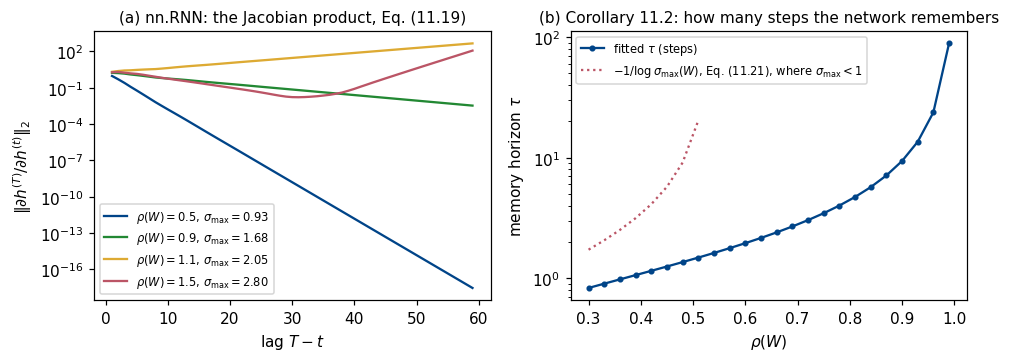

         fitted memory horizon tau (steps) and the lag for a factor 1e-6:
           rho=0.50  sigma_max=0.933  tau=  1.44  lag(1e-6)=  19.9
           rho=0.70  sigma_max=1.307  tau=  2.79  lag(1e-6)=  38.6
           rho=0.90  sigma_max=1.680  tau=  9.38  lag(1e-6)= 129.6
           rho=0.95  sigma_max=1.773  tau= 19.05  lag(1e-6)= 263.2
           rho=0.99  sigma_max=1.848  tau= 88.88  lag(1e-6)=1227.9
         logistic instead of tanh: mu=1/4, so at least a factor 4^59 = 3.3e+35 lost over 59 steps whatever the weights


          1.10     2.053        1.0000   4.547e+02     2.721e+18       -10.63


          1.50     2.800        0.9980   1.152e+02     2.410e+26       -20.40


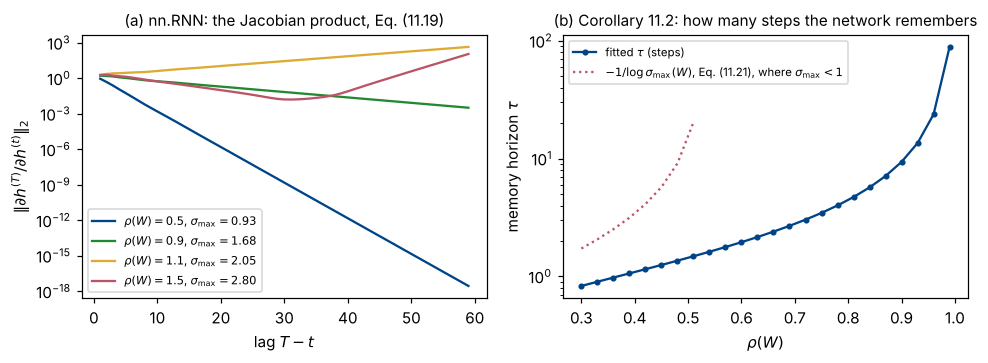

         fitted memory horizon tau (steps) and the lag for a factor 1e-6:


           rho=0.50  sigma_max=0.933  tau=  1.44  lag(1e-6)=  19.9


           rho=0.70  sigma_max=1.307  tau=  2.79  lag(1e-6)=  38.6


           rho=0.90  sigma_max=1.680  tau=  9.38  lag(1e-6)= 129.6


           rho=0.95  sigma_max=1.773  tau= 19.05  lag(1e-6)= 263.2


           rho=0.99  sigma_max=1.848  tau= 88.88  lag(1e-6)=1227.9
         logistic instead of tanh: mu=1/4, so at least a factor 4^59 = 3.3e+35 lost over 59 steps whatever the weights


In [9]:
rows = fig_gradients()

Two things to read off. At $\rho(\boldsymbol{W}) = 0.5$ the influence of
the first step on the last has fallen by eighteen orders of magnitude over
59 steps — the memory horizon is 1.4 steps. At $\rho = 1.1$ the same
quantity has grown to about $450$. The bound of Theorem 11.1 uses
$\sigma_{\max}(\boldsymbol{W})$, which for a random non-normal matrix is
larger than $\rho(\boldsymbol{W})$ ($0.93$ at $\rho = 0.5$, $1.7$ at
$\rho = 0.9$), so between $\rho < 1 < \sigma_{\max}$ there is a regime of
transient growth with asymptotic decay — where carefully initialised
recurrent networks actually operate. None of this depends on the library:
autograd computes the product of Eq. (11.19) exactly, and the vanishing
gradient is a property of the composition.

Gradient clipping, Eq. (11.23), handles explosion cheaply: it is the
projection of the gradient onto a ball of radius $\theta$ (Proposition 11.3),
so it preserves the descent direction and bounds the step by $\gamma\theta$.
It does nothing for vanishing gradients — rescaling $10^{-18}$ upwards would
amplify rounding noise, not signal. In Keras it is `clipnorm=1.0` on the
optimiser; in PyTorch `nn.utils.clip_grad_norm_` between `backward()` and
`step()`.

## Part 5: the oscillator experiment, in Keras and in PyTorch (Section 11.6.1)

One trajectory, $\eta = 0.2$, $(x_0, v_0) = (1, 0)$, no forcing, 800 points;
the network sees only $x(t)$ and is trained to predict $x_{i+1}$ at every
step along 152 overlapping windows of length 40 (`make_windows`). The
same network in both libraries: `SimpleRNN(24, return_sequences=True)` /
`nn.RNN(1, 24)` followed by a read-out at every step, Adam at
$5\cdot10^{-3}$, clipping at $\theta = 1$, batches of 4 windows, 300 epochs.
The tests are trajectories the network never saw: a different initial
condition, $(0, 1)$, out of phase with everything in the training data, and
an oscillator driven by $F(t) = 0.3\cos(0.7t)$. The PyTorch loop records the
gradient norm that `clip_grad_norm_` returns before clipping.

Two remarks on sequential data. Training and test *windows* may be shuffled,
the points inside a window may not — shuffling in time decorrelates the
series and leaks the future into the past; and the split is by whole
trajectories, so every test trajectory has a new initial condition. The cost
is the mean squared error of Eq. (11.5): a forecasting problem is a regression
problem.

In [10]:
def make_windows(x, L=40, stride=5):
    """One-step-ahead forecasting as sequence-to-sequence: inputs x_i..x_{i+L-1},
    targets x_{i+1}..x_{i+L}; arrays of shape (windows, L, 1)."""
    idx = range(0, len(x) - L - 1, stride)
    X = np.stack([x[i:i + L] for i in idx])[..., None].astype("float32")
    Y = np.stack([x[i + 1:i + L + 1] for i in idx])[..., None].astype("float32")
    return X, Y


def oscillator_data(L=40, stride=5):
    """Windows from the training trajectory (1,0) and from the two test trajectories."""
    ts, S_tr, S_ic, S_dr = oscillator_trajectories()
    data = {name: make_windows(S[:, 0], L, stride) for name, S in
            [("train", S_tr), ("unseen IC", S_ic), ("driven", S_dr)]}
    var = {name: float(S[:, 0].var()) for name, S in
           [("train", S_tr), ("unseen IC", S_ic), ("driven", S_dr)]}
    return data, var


def keras_oscillator(n_h=24, epochs=300, lr=5e-3, theta=1.0, batch=4, seed=0):
    """SimpleRNN(n_h, return_sequences=True) + Dense(1): Eq. (11.4) with an
    output at every step; Adam with clipnorm=theta is Eq. (11.23)."""
    from tensorflow import keras
    from tensorflow.keras import layers
    keras.utils.set_random_seed(seed)
    data, var = oscillator_data()
    Xtr, Ytr = data["train"]
    model = keras.Sequential([keras.Input(shape=(None, 1)),            # any length
                              layers.SimpleRNN(n_h, return_sequences=True),
                              layers.Dense(1)])                         # read-out at every step
    model.compile(optimizer=keras.optimizers.Adam(lr, clipnorm=theta), loss="mse")
    n_par = int(sum(np.prod(w.shape) for w in model.trainable_weights))
    t0 = time.time()
    hist = model.fit(Xtr, Ytr, epochs=epochs, batch_size=batch, verbose=0).history["loss"]
    res = {k: (float(model.evaluate(X, Y, verbose=0)), var[k]) for k, (X, Y) in data.items()}
    pred = {k: model.predict(data[k][0][::8][:12], verbose=0).ravel() for k in ("unseen IC", "driven")}
    true = {k: data[k][1][::8][:12].ravel() for k in ("unseen IC", "driven")}
    return dict(hist=np.array(hist), res=res, pred=pred, true=true, n_par=n_par,
                seconds=time.time() - t0, n_seq=len(Xtr))


def torch_oscillator(n_h=24, epochs=300, lr=5e-3, theta=1.0, batch=4, seed=0):
    """nn.RNN(1, n_h) + nn.Linear(n_h, 1) applied to every hidden state; the
    training loop records the gradient norm that clip_grad_norm_ sees."""
    import torch
    import torch.nn as nn
    torch.manual_seed(seed)
    data, var = oscillator_data()
    Xtr, Ytr = map(torch.tensor, data["train"])

    class Forecaster(nn.Module):
        def __init__(self):
            super().__init__()
            self.rnn = nn.RNN(1, n_h, batch_first=True)   # Eq. (11.4), tanh
            self.fc = nn.Linear(n_h, 1)                    # V h_t + c at every t

        def forward(self, x):
            H, h_T = self.rnn(x)                           # H: (N, T, n_h), all h_t
            return self.fc(H)                              # (N, T, 1)

    model = Forecaster()
    n_par = sum(q.numel() for q in model.parameters())
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    lossfn = nn.MSELoss()
    hist, gnorms, t0 = [], [], time.time()
    for ep in range(epochs):
        tot, nb = 0.0, 0
        for idx in torch.randperm(len(Xtr)).split(batch):  # windows shuffled, time inside kept
            opt.zero_grad(set_to_none=True)
            loss = lossfn(model(Xtr[idx]), Ytr[idx])
            loss.backward()                                            # BPTT
            gnorms.append(float(nn.utils.clip_grad_norm_(model.parameters(), theta)))  # Eq. (11.23)
            opt.step()
            tot += loss.item(); nb += 1
        hist.append(tot / nb)
    model.eval()
    with torch.no_grad():
        res = {k: (lossfn(model(torch.tensor(X)), torch.tensor(Y)).item(), var[k])
               for k, (X, Y) in data.items()}
        pred = {k: model(torch.tensor(data[k][0][::8][:12])).numpy().ravel()
                for k in ("unseen IC", "driven")}
    true = {k: data[k][1][::8][:12].ravel() for k in ("unseen IC", "driven")}
    return dict(hist=np.array(hist), res=res, pred=pred, true=true, n_par=n_par,
                gnorms=np.array(gnorms), theta=theta, seconds=time.time() - t0, n_seq=len(Xtr))


def fig_oscillator(K, P):
    fig, ax = plt.subplots(1, 4, figsize=(13.5, 3.1))
    ax[0].semilogy(np.arange(1, len(K["hist"]) + 1), K["hist"], color=BLUE, label="Keras SimpleRNN")
    ax[0].semilogy(np.arange(1, len(P["hist"]) + 1), P["hist"], color=RED, label="PyTorch nn.RNN")
    ax[0].set_xlabel("epoch")
    ax[0].set_ylabel("training mse, Eq. (11.5)")
    ax[0].set_title("(a) Adam, clipping at $\\theta=1$")
    ax[0].legend(fontsize=7.5)
    for a, key, title in [(ax[1], "unseen IC", "(b) unseen initial condition $(0,1)$"),
                          (ax[2], "driven", "(c) driven oscillator, never seen")]:
        a.plot(K["true"][key], color=GREY, lw=2.5, alpha=0.6, label="RK4")
        a.plot(K["pred"][key], color=BLUE, lw=0.9, label="Keras, one step ahead")
        a.plot(P["pred"][key], "--", color=RED, lw=0.9, label="PyTorch, one step ahead")
        a.set_title(title)
        a.set_xlabel("step (twelve test windows of length 40)")
        a.legend(fontsize=7.5)
    g = P["gnorms"]
    ax[3].hist(np.log10(g), bins=60, color=RED)
    ax[3].axvline(np.log10(P["theta"]), color=BLUE, ls="--", label=f"$\\theta={P['theta']}$")
    ax[3].set_xlabel("$\\log_{10}\\|\\nabla\\mathcal{L}\\|$ before clipping (PyTorch)")
    ax[3].set_title(f"(d) gradient norms: {int(np.sum(g > P['theta']))} of {len(g)} updates clipped")
    ax[3].legend(fontsize=7.5)
    fig.tight_layout()
    savefig(fig, "week45_oscillator")
    plt.close(fig)
    print(f"[Part 5] {K['n_seq']} training windows of length 40 from ONE trajectory; n_h=24; "
          f"Keras {K['n_par']} parameters ({K['seconds']:.0f} s), PyTorch {P['n_par']} ({P['seconds']:.0f} s)")
    print("           set          Keras mse   PyTorch mse   Var(x)   relative (Keras / PyTorch)")
    for k in K["res"]:
        ek, v = K["res"][k]
        ep, _ = P["res"][k]
        print(f"           {k:10s}  {ek:.3e}    {ep:.3e}   {v:.4f}   {ek/v:.3%} / {ep/v:.3%}")
    print(f"         PyTorch gradient norms before clipping: median {np.median(g):.3f}, "
          f"max {g.max():.2f}, {int(np.sum(g > P['theta']))} of {len(g)} above theta={P['theta']}")


In [ ]:
K = keras_oscillator()
P = torch_oscillator()
fig_oscillator(K, P)

The second row of the table is the interesting one: trained on a trajectory
starting from rest at unit displacement, tested on one starting from the
origin at unit velocity, the error is *the same as the training error* in
both libraries; the driven oscillator is predicted just as well. The network
has not memorised a trajectory, it has learned the *update rule*, which is
what Eq. (11.12) said it would do — the same payoff parameter sharing gave in
week 44. The two libraries differ by a factor of three in the final error
(different initialisations and batch orders), both far below anything that
matters. With $\sigma_{\max}(\boldsymbol{W}) \approx 1$ at the start and
sequences of 40 steps, clipping never fired; it is insurance.

## Part 6: three applications (Section 11.8)

(a) **A sine wave, one step ahead**: windows of 20 consecutive values
predict the next; `SimpleRNN(16)` with the default
`return_sequences=False` and `nn.RNN` with `out[:, -1, :]` both read the
last state only — the sequence-to-label case of Eq. (11.1). The split is in
*time*: the last 20 % of the wave is the test set.

In [ ]:
def sine_windows(seq_length=20, n=500):
    """A sine wave cut into overlapping windows; the target is the next value."""
    data = np.sin(np.linspace(0, 100, n)).astype("float32")
    X = np.stack([data[i:i + seq_length] for i in range(len(data) - seq_length)])[..., None]
    y = data[seq_length:].reshape(-1, 1)
    return X, y


def torch_sine(epochs=200, hidden=16, seed=1, lr=1e-2):
    """nn.RNN on the sine wave, Section 11.8.1; returns history, test predictions, parameters."""
    import torch
    import torch.nn as nn
    torch.manual_seed(seed)
    X, y = sine_windows()
    X, y = torch.tensor(X), torch.tensor(y)
    split = int(0.8 * len(X))

    class SineRNN(nn.Module):
        """nn.RNN implements Eq. (11.4) with tanh; we read out the last state only."""
        def __init__(self, hidden=16):
            super().__init__()
            self.rnn = nn.RNN(input_size=1, hidden_size=hidden, batch_first=True)
            self.fc = nn.Linear(hidden, 1)

        def forward(self, x):
            out, h_T = self.rnn(x)                 # out: (N, T, hidden)
            return self.fc(out[:, -1, :])          # sequence-to-label, Eq. (11.1)

    model = SineRNN(hidden)
    n_par = sum(q.numel() for q in model.parameters())
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    lossfn = nn.MSELoss()
    hist = []
    for epoch in range(1, epochs + 1):
        model.train()
        perm = torch.randperm(split)
        tot, nb = 0.0, 0
        for i in range(0, split, 32):
            idx = perm[i:i + 32]
            opt.zero_grad(set_to_none=True)
            loss = lossfn(model(X[idx]), y[idx])
            loss.backward()                                    # BPTT, Eqs. (11.16)-(11.18)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)  # Eq. (11.23)
            opt.step()
            tot += loss.item()
            nb += 1
        model.eval()
        with torch.no_grad():
            te = lossfn(model(X[split:]), y[split:]).item()
        hist.append((epoch, tot / nb, te))
    with torch.no_grad():
        pred = model(X[split:]).numpy().ravel()
    return np.array(hist), pred, y[split:].numpy().ravel(), n_par


def keras_sine(epochs=200, hidden=16, seed=1, lr=1e-2):
    """SimpleRNN on the sine wave: exactly Eq. (11.4), tanh by default."""
    from tensorflow import keras
    from tensorflow.keras import layers
    keras.utils.set_random_seed(seed)
    X, y = sine_windows()
    split = int(0.8 * len(X))
    model = keras.Sequential([keras.Input(shape=(X.shape[1], 1)),
                              layers.SimpleRNN(hidden), layers.Dense(1)])
    model.compile(optimizer=keras.optimizers.Adam(lr, clipnorm=1.0), loss="mse")
    n_par = int(sum(np.prod(w.shape) for w in model.trainable_weights))
    h = model.fit(X[:split], y[:split], epochs=epochs, batch_size=32, verbose=0,
                  validation_data=(X[split:], y[split:]))
    hist = np.column_stack([np.arange(1, epochs + 1), h.history["loss"], h.history["val_loss"]])
    return hist, model.predict(X[split:], verbose=0).ravel(), y[split:].ravel(), n_par


def fig_sine(ht, pt, yt, npt, hk, pk, yk, npk):
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
    ax[0].plot(yt, color=GREY, lw=3, alpha=0.5, label="true")
    ax[0].plot(pt, color=RED, lw=0.9, label=f"PyTorch nn.RNN ({npt} parameters)")
    ax[0].plot(pk, "--", color=BLUE, lw=0.9, label=f"Keras SimpleRNN ({npk} parameters)")
    ax[0].set_xlabel("held-out window")
    ax[0].set_title("(a) one-step forecasts on the last 20% of the sine wave")
    ax[0].legend(fontsize=7.5)
    ax[1].semilogy(ht[:, 0], ht[:, 2], color=RED, label="PyTorch test mse")
    ax[1].semilogy(hk[:, 0], hk[:, 2], color=BLUE, label="Keras test mse")
    ax[1].semilogy(ht[:, 0], ht[:, 1], ":", color=RED, lw=0.8, label="PyTorch train")
    ax[1].semilogy(hk[:, 0], hk[:, 1], ":", color=BLUE, lw=0.8, label="Keras train")
    ax[1].set_xlabel("epoch")
    ax[1].set_title("(b) mean squared error, Adam, batches of 32")
    ax[1].legend(fontsize=7.5)
    fig.tight_layout()
    savefig(fig, "week45_sine")
    plt.close(fig)
    print(f"[Part 6a] sine wave, 200 epochs: PyTorch train mse {ht[-1,1]:.6f} test {ht[-1,2]:.6f} "
          f"({npt} parameters); Keras train {hk[-1,1]:.6f} test {hk[-1,2]:.6f} ({npk} parameters); "
          f"rms error {np.sqrt(ht[-1,2]):.4f} / {np.sqrt(hk[-1,2]):.4f} on a signal of amplitude 1")


In [ ]:
ht, pt, yt, npt = torch_sine()
hk, pk, yk, npk = keras_sine()
fig_sine(ht, pt, yt, npt, hk, pk, yk, npk)

(b) **MNIST read row by row**: each $28\times28$ image as a sequence of 28
rows of 28 features, classified from the last state by a simple RNN with
$n_h = 128$; three epochs, Adam $10^{-3}$, batches of 64, the full 60 000
images from `mnist.npz`. Not what one does in practice — the recap of week
44 said why a CNN is the right tool — but a clean sequence-to-label task
and a direct comparison: the code is the CNN program with the layer in the
middle exchanged. (`cell="lstm"` runs the gated version for next week.)

In [ ]:
def load_mnist_rows():
    """MNIST from the local mnist.npz as 28 rows of 28 features, scaled to [0,1]."""
    d = np.load(os.path.join(HERE, "mnist.npz"))
    xtr = d["x_train"].astype("float32") / 255.0
    xte = d["x_test"].astype("float32") / 255.0
    return (xtr, d["y_train"].astype("int64")), (xte, d["y_test"].astype("int64"))


def torch_mnist_rows(cell="lstm", epochs=3, hidden=128, seed=1):
    """MNIST read row by row with nn.LSTM or nn.RNN, Section 11.8.2."""
    import torch
    import torch.nn as nn
    torch.manual_seed(seed)
    (xtr, ytr), (xte, yte) = load_mnist_rows()
    Xtr, Ytr, Xte, Yte = map(torch.tensor, (xtr, ytr, xte, yte))

    class RowNet(nn.Module):
        def __init__(self):
            super().__init__()
            C = {"rnn": nn.RNN, "lstm": nn.LSTM, "gru": nn.GRU}[cell]
            self.rnn = C(28, hidden, batch_first=True)   # 28 time steps of 28 features
            self.fc = nn.Linear(hidden, 10)

        def forward(self, x):
            return self.fc(self.rnn(x)[0][:, -1, :])     # last state -> class scores

    net = RowNet()
    n_par = sum(q.numel() for q in net.parameters())
    opt = torch.optim.Adam(net.parameters(), lr=1e-3)
    lf = nn.CrossEntropyLoss()
    rows, t0 = [], time.time()
    for ep in range(1, epochs + 1):
        net.train()
        perm = torch.randperm(len(Xtr))
        tot, nb = 0.0, 0
        for i in range(0, len(Xtr) - 64 + 1, 64):
            idx = perm[i:i + 64]
            opt.zero_grad(set_to_none=True)
            loss = lf(net(Xtr[idx]), Ytr[idx])
            loss.backward()
            nn.utils.clip_grad_norm_(net.parameters(), 1.0)
            opt.step()
            tot += loss.item()
            nb += 1
        net.eval()
        with torch.no_grad():
            pred = torch.cat([net(Xte[i:i + 1000]).argmax(1) for i in range(0, len(Xte), 1000)])
            acc = (pred == Yte).double().mean().item()
        rows.append((ep, tot / nb, acc, time.time() - t0))
    return np.array(rows), n_par


def keras_mnist_rows(cell="lstm", epochs=3, hidden=128, seed=1):
    """The same two networks in Keras."""
    from tensorflow import keras
    from tensorflow.keras import layers
    keras.utils.set_random_seed(seed)
    (xtr, ytr), (xte, yte) = load_mnist_rows()
    Layer = {"lstm": layers.LSTM, "rnn": layers.SimpleRNN, "gru": layers.GRU}[cell]
    m = keras.Sequential([keras.Input(shape=(28, 28)), Layer(hidden), layers.Dense(10)])
    m.compile(optimizer=keras.optimizers.Adam(1e-3, clipnorm=1.0),
              loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=["accuracy"])
    n_par = int(sum(np.prod(w.shape) for w in m.trainable_weights))
    rows, t0 = [], time.time()
    for ep in range(1, epochs + 1):
        hh = m.fit(xtr, ytr, epochs=1, batch_size=64, verbose=0)
        _, acc = m.evaluate(xte, yte, verbose=0)
        rows.append((ep, hh.history["loss"][0], acc, time.time() - t0))
    return np.array(rows), n_par


def fig_mnist_rows(results):
    """results: dict (framework, cell) -> (rows, n_par)."""
    fig, ax = plt.subplots(1, 1, figsize=(6.2, 3.3))
    styles = {("PyTorch", "lstm"): (RED, "-"), ("PyTorch", "rnn"): (RED, "--"),
              ("TensorFlow", "lstm"): (BLUE, "-"), ("TensorFlow", "rnn"): (BLUE, "--")}
    print("[Part 6b] MNIST as 28 rows of 28, three epochs, Adam 1e-3, batches of 64, n_h=128:")
    print("           cell        framework    parameters  test accuracy  seconds")
    for (fw, cell), (rows, n_par) in results.items():
        c, ls = styles[(fw, cell)]
        ax.plot(rows[:, 0], 100 * rows[:, 2], ls, marker="o", ms=4, color=c,
                label=f"{fw} {'LSTM' if cell == 'lstm' else 'simple RNN'} ({n_par} par.)")
        print(f"           {cell:10s}  {fw:11s}  {n_par:10d}  {rows[-1,2]:13.4f}  {rows[-1,3]:7.0f}")
    ax.set_xlabel("epoch")
    ax.set_ylabel("test accuracy (%)")
    ax.set_xticks([1, 2, 3])
    ax.set_title("MNIST read row by row" + (": LSTM against simple RNN" if any(c == "lstm" for _, c in results) else ": simple RNN"))
    ax.legend(fontsize=7.5)
    fig.tight_layout()
    savefig(fig, "week45_mnist_rows")
    plt.close(fig)


In [ ]:
res = {("PyTorch", "rnn"): torch_mnist_rows("rnn"),
       ("TensorFlow", "rnn"): keras_mnist_rows("rnn")}
fig_mnist_rows(res)

A simple recurrent layer with 21 000 parameters reads the image in 28 steps
and reaches 93–96 % — the task is within its memory horizon — where the
convolutional network of week 44 reached 99 %: reading an image as a
sequence throws away the vertical structure that a CNN was built to exploit.

(c) **The adding problem** (Section 11.8.5): two channels, uniform values
and two markers, one in each half of the sequence; the target is half the sum
of the two marked values. Nothing can be inferred from local statistics, so
the model must hold one number across the sequence while ignoring everything
in between. Predicting the mean and stopping gives a mean squared error of
about $0.043$. We train `nn.RNN` with $n_h = 32$ at $T = 10, 30, 60, 120$,
same seed, optimiser and epochs — the experiment that shows where the memory
horizon of Corollary 11.2 runs out. (The same function with
`cells=("rnn", "lstm", "gru")` is the comparison of next week.)

In [ ]:
def adding_problem(n, T, rng):
    """Two channels: uniform values and two markers, one in each half; the
    target is half the sum of the two marked values (Section 11.8.5)."""
    v = rng.uniform(0, 1, (n, T)).astype("float32")
    m = np.zeros((n, T), dtype="float32")
    i1 = rng.integers(0, T // 2, n)
    i2 = rng.integers(T // 2, T, n)
    m[np.arange(n), i1] = 1.0
    m[np.arange(n), i2] = 1.0
    y = (v[np.arange(n), i1] + v[np.arange(n), i2]).reshape(-1, 1) / 2.0
    return np.stack([v, m], -1), y


def torch_adding(lags=(10, 30, 60, 120), cells=("rnn", "lstm", "gru"), seeds=(0,),
                 epochs=40, hidden=32, verbose=True):
    """The adding problem at increasing sequence length; returns table (cells x lags) and baseline."""
    import torch
    import torch.nn as nn
    table = np.zeros((len(cells), len(lags)))
    base_row = np.zeros(len(lags))
    if verbose:
        print("[Part 6d] the adding problem, held-out mse (predicting the mean gives the baseline):")
        print("            T   baseline" + "".join(f"{c:>10s}" for c in cells))
    for j, T in enumerate(lags):
        Xr, yr = adding_problem(3000, T, np.random.default_rng(3))
        Xv, yv = adding_problem(1000, T, np.random.default_rng(4))
        Xr, yr, Xv, yv = map(torch.tensor, (Xr, yr, Xv, yv))
        base_row[j] = float(((yv - yv.mean()) ** 2).mean())
        line = f"          {T:4d} {base_row[j]:9.4f}"
        for i, cell in enumerate(cells):
            runs = []
            for sd in seeds:
                torch.manual_seed(sd)
                C = {"rnn": nn.RNN, "lstm": nn.LSTM, "gru": nn.GRU}[cell]
                core, head = C(2, hidden, batch_first=True), nn.Linear(hidden, 1)
                params = list(core.parameters()) + list(head.parameters())
                opt = torch.optim.Adam(params, lr=5e-3)
                lf = nn.MSELoss()
                for ep in range(epochs):
                    perm = torch.randperm(len(Xr))
                    for k in range(0, len(Xr), 64):
                        idx = perm[k:k + 64]
                        opt.zero_grad(set_to_none=True)
                        loss = lf(head(core(Xr[idx])[0][:, -1, :]), yr[idx])
                        loss.backward()
                        nn.utils.clip_grad_norm_(params, 1.0)
                        opt.step()
                with torch.no_grad():
                    runs.append(lf(head(core(Xv)[0][:, -1, :]), yv).item())
            table[i, j] = np.mean(runs)
            line += f"{table[i, j]:10.4f}"
        if verbose:
            print(line)
    return np.array(lags), table, base_row


def fig_adding(lags, table, base, cells=("rnn", "lstm", "gru")):
    fig, ax = plt.subplots(figsize=(6.2, 3.3))
    ax.set_ylim(5e-6, 0.1)
    for i, (cell, c) in enumerate(zip(cells, [RED, BLUE, GREEN])):
        ax.semilogy(lags, np.maximum(table[i], 1e-5), "o-", color=c,
                    label={"rnn": "simple RNN", "lstm": "LSTM", "gru": "GRU"}[cell])
    ax.semilogy(lags, base, ":", color=GREY, label="predict the mean")
    ax.set_xlabel("sequence length $T$")
    ax.set_ylabel("held-out mean squared error")
    ax.set_title("The adding problem: where the memory horizon runs out")
    ax.legend(fontsize=8)
    fig.tight_layout()
    savefig(fig, "week45_adding" + ("" if len(cells) == 1 else "_gated"))
    plt.close(fig)


            30    0.0429    0.0410


            60    0.0411    0.0405


           120    0.0425    0.0426


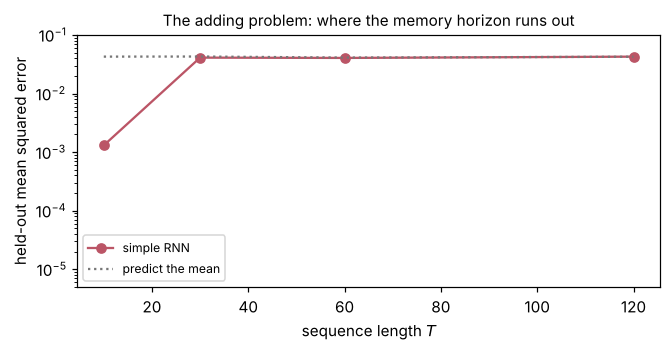

In [ ]:
lags, table, base = torch_adding(cells=("rnn",))
fig_adding(lags, table, base, cells=("rnn",))

At $T = 10$ the simple recurrent network solves the task, $0.0013$ against
a baseline of $0.0427$. At $T = 30$ it has already failed completely — an
error equal to the baseline is the error of a model that outputs the mean
and nothing else — and it never recovers at 60 or 120. Corollary 11.2
predicted this: a simple RNN initialised in the usual way has a horizon of a
few steps, so a dependency at lag 30 is invisible to it. The gap between
$T = 10$ and $T = 30$ is where the horizon runs out. Next Monday we change
the cell, keep everything else in this code, and run the same table again.

## Summary

A CNN shares its parameters along the spatial axes; a recurrent network
shares them along the time axis. The simple RNN is a learned dynamical
system — the oscillator showed it is a learned time-stepping scheme — and in
the libraries it is one layer, `SimpleRNN` or `nn.RNN`, fed a
`(samples, timesteps, features)` tensor in the same `Sequential` /
training-loop pattern as the CNN. `loss.backward()` and `model.fit` perform
backpropagation through time exactly: a linear backward pass whose gradient
across a lag is a product of Jacobians — $10^{-18}$ over 59 steps at
$\rho(\boldsymbol{W}) = 0.5$, a memory horizon of 1.4 steps, measured with
autograd. Clipping handles explosion for free and does nothing for
vanishing. Trained on one damped oscillation the simple cell predicted an
unseen initial condition and an unseen forcing at the training error; it
reads MNIST in 28 steps at 93–96 %; and on the adding problem it fails from
$T = 30$, exactly where Corollary 11.2 says its memory runs out. Next
Monday: the gated cells that do not.

**Reading:** Chapter 11, Sections 11.1–11.6 and 11.8; Goodfellow et al.
Chapter 10; Raschka et al. Chapter 15. **Tomorrow:** work on Project 2
(deadline Monday November 9). **Next Monday, week 46:** first hour LSTM and
GRU (Section 11.7) with the adding problem and spoken digits, then decision
trees and ensemble methods (Chapter 7).